In [2]:
%cd ..
from actions import *
%cd testing/
import matplotlib.pyplot as plt
import os
import numpy

/Users/m02n1n6/Frenkel_Hamiltonian
/Users/m02n1n6/Frenkel_Hamiltonian/testing


## Testing the code on a BChl trimer  
This Jupyter Notebook show the use of the `'action'` module for the creation of theb Frenkel-Davydov Hamiltonian of a trimer.
As an example, a trimer of BChls from LH2 has been considered.

* The Hamiltonian can be built from the data by hand by considering the total coupling terms among the monomers. 


In [3]:
hand_made_frenkel = np.array([
    [0.00000000000, 0.00553812445, 0.03597006796, 0.01956224835, -0.00845320248, 0.03924104590, 0.00742817870, -0.01170381015, -0.01492477464, 0.01872656081, -0.01047406898, 0.00389682813, 0.00982988668],
    [0.00553812445, 1.62304685000, 0.01259439600, -0.02037300301, -0.01083027952, 0.04912327850, 0.00977321356, 0.00192839072, -0.00113962492, -0.00926702028, -0.00065481985, -0.00026444638, -0.00028948097],
    [0.03597006796, 0.01259439600, 2.38517076000, -0.00100399323, 0.00404676709, -0.00203175513, 0.01020117040, -0.00118441442, -0.00693809197, -0.00113837136, 0.00100026063, 0.00029486195, -0.00044518007],
    [0.01956224835, -0.02037300301, -0.00100399323, 2.57597074000, -0.00022567439, -0.00099065399, 0.01093089790, -0.00008742136, -0.00708876116, -0.00055527568, 0.00079533820, 0.00021619015, -0.00035650567],
    [-0.00845320248, -0.01083027952, 0.00404676709, -0.00022567439, 2.98468396000, -0.00464103332, 0.00139373933, -0.00063236379, -0.00032995637, 0.00058724525, 0.00014879725, 0.00002117739, -0.00001361845],
    [0.03924104590, 0.04912327850, -0.00203175513, -0.00099065399, -0.00464103332, 1.59408777000, 0.01234293477, -0.02807699632, 0.00520236280, 0.04653698520, -0.00243624575, -0.00148661443, 0.00697573767],
    [0.00742817870, 0.00977321356, 0.01020117040, 0.01093089790, 0.00139373933, 0.01234293477, 2.40781521000, -0.01165567525, 0.01522695496, 0.00519009690, 0.01320167100, 0.00229591637, -0.00583177640],
    [-0.01170381015, 0.00192839072, -0.00118441442, -0.00008742136, -0.00063236379, -0.02807699632, -0.01165567525, 2.54370933000, -0.00400101229, -0.00908097332, 0.00123543174, 0.00085384819, -0.00220061613],
    [-0.01492477464, -0.00113962492, -0.00693809197, -0.00708876116, -0.00032995637, 0.00520236280, 0.01522695496, -0.00400101229, 2.91861996000, 0.00139235237, 0.00277880816, 0.00008354219, -0.00112365787],
    [0.01872656081, -0.00926702028, -0.00113837136, -0.00055527568, 0.00058724525, 0.04653698520, 0.00519009690, -0.00908097332, 0.00139235237, 1.65455313000, 0.00458905771, -0.00173274797, 0.00752918554],
    [-0.01047406898, -0.00065481985, 0.00100026063, 0.00079533820, 0.00014879725, -0.00243624575, 0.01320167100, 0.00123543174, 0.00277880816, 0.00458905771, 2.39485446000, -0.00584140905, 0.00180215761],
    [0.00389682813, -0.00026444638, 0.00029486195, 0.00021619015, 0.00002117739, -0.00148661443, 0.00229591637, 0.00085384819, 0.00008354219, -0.00173274797, -0.00584140905, 2.66923043000, -0.00245985543],
    [0.00982988668, -0.00028948097, -0.00044518007, -0.00035650567, -0.00001361845, 0.00697573767, -0.00583177640, -0.00220061613, -0.00112365787, 0.00752918554, 0.00180215761, -0.00245985543, 3.03398957000]
])

**Then we need:**
* to set the first monomer and the last, to build the trimer in this case;
* to say the total number of states used in the CASSCF calculation;
* to set the number of states considered in the Frenkel Hamiltonian per monomer;

In [4]:
first_monomer = 301
last_monomer = 303
total_roots = 5 # total number of states used in the CASSCF calculation;
dim = 5 # number of states considered in the Frenkel Hamiltonian per monomer;

#### Collect the data  
Use the `collect` function inside the `actions` module to collect:  
* the coupling terms, 
* the excitation energies of the monomers and 
* the transition dipole moments

In [5]:
C, E, TDM = collect(first_monomer=first_monomer, 
                    last_monomer=last_monomer, 
                    computed_roots=total_roots,
                    source = os.getcwd(),
                    wanted_roots=dim)

#### Create the corresponding Frenkel Hamiltonian  
Use the `build` function inside the `actions` module to build the Frenkel-Davydov Hamiltonian corresponding to the parameters we set.  
The unit of measurement is 'Hartree' by default, but can be set to 'eV'.

In [6]:
Frenkel = build(E=E,
                C=C,
                units='eV')

#### Create the corresponding Frenkel Hamiltonian  
Use the `build` function inside the `actions` module to build the Frenkel-Davydov Hamiltonian corresponding to the parameters we set.  
The unit of measurement is 'Hartree' by default, but can be set to 'eV'.

#### Check the Frenkel Hamiltonian  

Check that the difference between the result and the hand-made Hamiltonian corresponds (up to small numerical/truncation differences)

In [7]:
diff = hand_made_frenkel - Frenkel
print(np.all(diff <= 10e9))

True


#### Compute the physical properties of the trimer  

To do that, use the `compute` function.

In [8]:
eigenvalues, eigenvectors, oscillators, TDM_EXC = compute(Frenkel=Frenkel,
                                                TDM=TDM,
                                                printed_output=False)

if `printed_output=True` a `.out` file is generated. To see an example of the file open `trimer_demo.out`

These data can be analysed as we wish, but also used to generate a spectrum of the system using the function `get_spectrum` which give the x and y-axis of the spectrum.


In [11]:
x_axis, y_axis = get_spectrum(E=eigenvalues,
                              f = oscillators,
                              sigma=0.05) # standard deviation of the Gaussian function

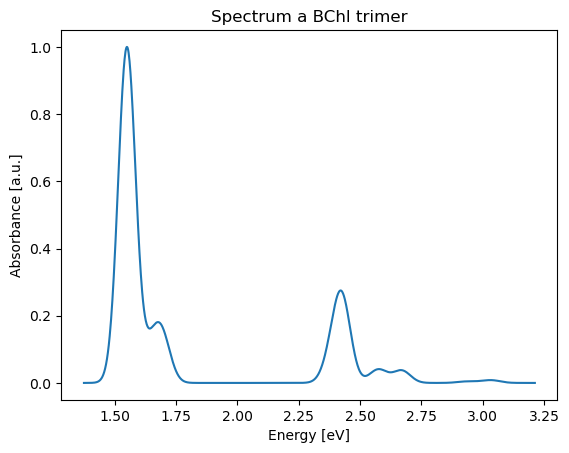

In [12]:
plt.plot(x_axis,y_axis)
plt.xlabel("Energy [eV]")
plt.ylabel("Absorbance [a.u.]")
plt.title("Spectrum a BChl trimer")
plt.show()